# Lab 3 - homework

In [1]:
from datetime import date

import polars as pl

DATA_DIR = "data"

## 1. Data reading
   - load all 2024 months of taxi rides
   - also load taxi zone lookup data
   - include only rides starting in 2024 and ending at most at 01.01.2025
   - optimize data types, particularly for integers and categorical strings

In [2]:
df_taxi_zones = pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv").with_columns(
    pl.col("LocationID").cast(pl.UInt16),
    pl.col("Borough").cast(pl.Categorical),
    pl.col("Zone").cast(pl.Categorical),
    pl.col("service_zone").cast(pl.Categorical),
)

df_taxi_zones.collect_schema()

Schema([('LocationID', UInt16),
        ('Borough', Categorical(ordering='physical')),
        ('Zone', Categorical(ordering='physical')),
        ('service_zone', Categorical(ordering='physical'))])

In [3]:
dfs = []
for month in range(1, 13):
    df_month = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet").with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    dfs.append(df_month)

df = (
    pl.concat(dfs)
    .filter(
        pl.col("tpep_pickup_datetime").dt.year() == 2024,
        pl.col("tpep_dropoff_datetime").dt.date() <= date(2025, 1, 1),
    )
    .with_columns(
        pl.col("VendorID").cast(pl.UInt8),
        pl.col("passenger_count").cast(pl.UInt8),
        pl.col("RatecodeID").cast(pl.UInt8),
        pl.col("PULocationID").cast(pl.UInt16),
        pl.col("DOLocationID").cast(pl.UInt16),
        pl.col("payment_type").cast(pl.UInt8),
        pl.col("store_and_fwd_flag").cast(pl.Categorical),
    )
)

df.collect_schema()

Schema([('VendorID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', UInt8),
        ('trip_distance', Float64),
        ('RatecodeID', UInt8),
        ('store_and_fwd_flag', Categorical(ordering='physical')),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt8),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

## 2. Data cleaning and filtering
   - fill NULL values in `passengers_count` with 1
   - remove rides with zero passengers
   - if a ride has over 6 passengers, replace the value with 6
   - remove rides lasting over 2 hours
   - in all money-related columns, replace values with absolute value to fix negative amounts
   - remove rides with over 1000 dollars in any money-related column
   - remove rows with values of `RatecodeID` or `VendorID` missing or outside those defined in the data dictionary

In [4]:
money_columns = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

df = (
    df
    .with_columns(pl.col("passenger_count").fill_null(1))
    .filter(pl.col("passenger_count") != 0)
    .with_columns(pl.col("passenger_count").clip(upper_bound=6))
    .filter(pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime") <= pl.duration(hours=2))
    .with_columns(pl.col(money_columns).abs())
    .filter(pl.all_horizontal(pl.col(money_columns) <= 1000))
    .filter(
        pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6]),
        pl.col("VendorID").is_in([1, 2, 6, 7]),
    )
)

df.collect_schema()

Schema([('VendorID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', UInt8),
        ('trip_distance', Float64),
        ('RatecodeID', UInt8),
        ('store_and_fwd_flag', Categorical(ordering='physical')),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt8),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

## 3. Data transformation
   - combine payment type values for `"No charge"`, `"Dispute"`, `"Unknown"` and `"Voided trip"` into one type,
     so we have only credit card, cash, or other
   - replace `PULocationID` and `DOLocationID` with borough names by joining taxi zone lookup and removing
     unnecessary columns
   - add boolean variable `is_airport_ride`, true if there is non-zero airport fee
   - add boolean variable `is_rush_hour`, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

In [5]:
df = (
    df
    .with_columns(
        pl.col("payment_type")
        .replace_strict({1: "card", 2: "cash"}, default="other")
        .cast(pl.Categorical)
    )
    .join(
        df_taxi_zones.select("LocationID", pl.col("Borough").alias("pickup_borough")),
        left_on="PULocationID",
        right_on="LocationID",
    )
    .join(
        df_taxi_zones.select("LocationID", pl.col("Borough").alias("dropoff_borough")),
        left_on="DOLocationID",
        right_on="LocationID",
    )
    .drop("PULocationID", "DOLocationID")
    .with_columns((pl.col("Airport_fee") > 0).alias("is_airport_ride"))
    .with_columns(
        (
            (pl.col("tpep_pickup_datetime").dt.weekday() <= 5)
            & (
                pl.col("tpep_pickup_datetime").dt.time().is_between(pl.time(6, 30), pl.time(9, 30))
                | pl.col("tpep_pickup_datetime").dt.time().is_between(pl.time(15, 30), pl.time(20))
            )
        ).alias("is_rush_hour")
    )
)

df.collect_schema()

Schema([('VendorID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', UInt8),
        ('trip_distance', Float64),
        ('RatecodeID', UInt8),
        ('store_and_fwd_flag', Categorical(ordering='physical')),
        ('payment_type', Categorical(ordering='physical')),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64),
        ('pickup_borough', Categorical(ordering='physical')),
        ('dropoff_borough', Categorical(ordering='physical')),
        ('is_airport_ride', Boolean),
        ('is_rush_hour', Boolean)])

## 4. Feature extraction
   - apply dummy encoding to features:
     - payment type
     - pickup borough
     - dropoff borough
   - add integer variables for counting daily events:
     - total number of rides (target variable)
     - number of airport rides
     - number of rush hour rides
   - add features aggregating daily rides information:
     - average fare amount
     - median distance
     - sum of total amounts
     - total amount paid by card, cash, and other
     - total congestion surcharge
     - total number of passengers
   - add time features:
     - `quarter`
     - `month`
     - `day_of_month`
     - `day_of_week`
     - `is_weekend` (boolean)
   - add column `date`, indicating day with given features
   - make sure to exclude other columns, unnecessary for machine learning, e.g. IDs, timestamps, unused financial information
   - properly name all columns
   - save results as `dataset.parquet` file

In [6]:
df_dataset = (
    df
    .select(
        "tpep_pickup_datetime",
        "payment_type",
        "pickup_borough",
        "dropoff_borough",
        "is_airport_ride",
        "is_rush_hour",
        "fare_amount",
        "trip_distance",
        "total_amount",
        "congestion_surcharge",
        "passenger_count",
    )
    .collect()
    .to_dummies(["payment_type", "pickup_borough", "dropoff_borough"])
    .lazy()
    .with_columns(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
    .group_by("date")
    .agg(
        pl.len().alias("num_rides"),
        pl.col("is_airport_ride").sum().alias("num_airport_rides"),
        pl.col("is_rush_hour").sum().alias("num_rush_hour_rides"),
        pl.col("^(payment_type|pickup_borough|dropoff_borough)_.*$").sum().name.prefix("num_rides_"),
        pl.col("fare_amount").mean().alias("avg_fare_amount"),
        pl.col("trip_distance").median().alias("median_trip_distance"),
        pl.col("total_amount").sum().alias("sum_total_amount"),
        pl.col("total_amount").filter(pl.col("payment_type_card") == 1).sum().alias("sum_total_amount_card"),
        pl.col("total_amount").filter(pl.col("payment_type_cash") == 1).sum().alias("sum_total_amount_cash"),
        pl.col("total_amount").filter(pl.col("payment_type_other") == 1).sum().alias("sum_total_amount_other"),
        pl.col("congestion_surcharge").sum().alias("sum_congestion_surcharge"),
        pl.col("passenger_count").sum().alias("num_passengers"),
    )
    .with_columns(
        pl.col("date").dt.quarter().alias("quarter"),
        pl.col("date").dt.month().alias("month"),
        pl.col("date").dt.day().alias("day_of_month"),
        pl.col("date").dt.weekday().alias("day_of_week"),
        (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
    )
    .rename(lambda name: name.lower().replace(" ", "_").replace("/", ""))
    .sort("date")
    .collect()
)

df_dataset

date,num_rides,num_airport_rides,num_rush_hour_rides,num_rides_payment_type_card,num_rides_payment_type_cash,num_rides_payment_type_other,num_rides_pickup_borough_bronx,num_rides_pickup_borough_brooklyn,num_rides_pickup_borough_ewr,num_rides_pickup_borough_manhattan,num_rides_pickup_borough_na,num_rides_pickup_borough_queens,num_rides_pickup_borough_staten_island,num_rides_pickup_borough_unknown,num_rides_dropoff_borough_bronx,num_rides_dropoff_borough_brooklyn,num_rides_dropoff_borough_ewr,num_rides_dropoff_borough_manhattan,num_rides_dropoff_borough_na,num_rides_dropoff_borough_queens,num_rides_dropoff_borough_staten_island,num_rides_dropoff_borough_unknown,avg_fare_amount,median_trip_distance,sum_total_amount,sum_total_amount_card,sum_total_amount_cash,sum_total_amount_other,sum_congestion_surcharge,num_passengers,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,i64,i8,i8,i8,i8,bool
2024-01-01,69541,8352,19360,52846,14491,2204,60,627,21,59231,93,9235,3,271,559,3785,388,58579,605,5150,31,444,22.184388,2.09,2.1793e6,1.7389e6,384662.67,55778.86,156123.25,109013,1,1,1,1,false
2024-01-02,71443,9828,30554,54034,15387,2022,34,232,20,60126,54,10709,2,266,433,2979,319,62212,432,4651,32,385,21.312124,1.8,2.2095e6,1.7617e6,396334.47,51441.03,160615.0,102927,1,1,2,2,false
2024-01-03,78399,9140,32924,60176,16202,2021,48,301,16,67701,36,9981,1,315,498,3124,282,69273,395,4340,14,473,19.968751,1.72,2.2900e6,1.8242e6,416241.57,49554.25,177985.0,109805,1,1,3,3,false
2024-01-04,97896,8270,43112,77557,17994,2345,42,257,10,88136,39,9026,1,385,596,3089,226,88692,344,4386,14,549,18.68711,1.73,2.7179e6,2.2134e6,444631.77,59823.2,226627.5,134634,1,1,4,4,false
2024-01-05,97958,7460,40150,77801,17697,2460,47,298,8,88955,37,8218,1,394,536,2889,222,89122,342,4220,20,607,18.114238,1.7,2.6451e6,2.1666e6,420694.52,57798.23,227540.0,136260,1,1,5,5,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-12-27,78785,7275,30013,58973,15878,3934,39,354,23,68690,46,9445,1,187,380,3207,242,70116,402,4187,20,231,21.094862,1.74,2.4050e6,1.8816e6,412246.55,111233.75,181365.0,121196,4,12,27,5,false
2024-12-28,81437,6848,0,60049,17306,4082,58,362,21,71557,81,9116,6,236,468,3418,266,72233,425,4306,26,295,20.185737,1.69,2.3216e6,1.7808e6,431258.45,109513.49,187202.5,127761,4,12,28,6,true
2024-12-29,73187,7751,0,54483,14600,4104,31,457,26,62132,77,10266,5,193,436,3988,280,62942,506,4790,19,226,22.155821,1.9,2.2688e6,1.7720e6,379363.29,117366.18,165090.0,114408,4,12,29,7,true


In [7]:
df_dataset.write_parquet(f"{DATA_DIR}/dataset.parquet")

## 5. Data analysis
   - print shape
   - show top rows
   - describe statistics
   - print schema
   - plot target variable (daily number of rides):
     - histogram of values
     - line plot, date vs number of rides (remember to sort by date)

In [8]:
df_dataset.shape

(366, 36)

In [9]:
df_dataset.head()

date,num_rides,num_airport_rides,num_rush_hour_rides,num_rides_payment_type_card,num_rides_payment_type_cash,num_rides_payment_type_other,num_rides_pickup_borough_bronx,num_rides_pickup_borough_brooklyn,num_rides_pickup_borough_ewr,num_rides_pickup_borough_manhattan,num_rides_pickup_borough_na,num_rides_pickup_borough_queens,num_rides_pickup_borough_staten_island,num_rides_pickup_borough_unknown,num_rides_dropoff_borough_bronx,num_rides_dropoff_borough_brooklyn,num_rides_dropoff_borough_ewr,num_rides_dropoff_borough_manhattan,num_rides_dropoff_borough_na,num_rides_dropoff_borough_queens,num_rides_dropoff_borough_staten_island,num_rides_dropoff_borough_unknown,avg_fare_amount,median_trip_distance,sum_total_amount,sum_total_amount_card,sum_total_amount_cash,sum_total_amount_other,sum_congestion_surcharge,num_passengers,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,i64,i8,i8,i8,i8,bool
2024-01-01,69541,8352,19360,52846,14491,2204,60,627,21,59231,93,9235,3,271,559,3785,388,58579,605,5150,31,444,22.184388,2.09,2.1793e6,1.7389e6,384662.67,55778.86,156123.25,109013,1,1,1,1,false
2024-01-02,71443,9828,30554,54034,15387,2022,34,232,20,60126,54,10709,2,266,433,2979,319,62212,432,4651,32,385,21.312124,1.8,2.2095e6,1.7617e6,396334.47,51441.03,160615.0,102927,1,1,2,2,false
2024-01-03,78399,9140,32924,60176,16202,2021,48,301,16,67701,36,9981,1,315,498,3124,282,69273,395,4340,14,473,19.968751,1.72,2.2900e6,1.8242e6,416241.57,49554.25,177985.0,109805,1,1,3,3,false
2024-01-04,97896,8270,43112,77557,17994,2345,42,257,10,88136,39,9026,1,385,596,3089,226,88692,344,4386,14,549,18.68711,1.73,2.7179e6,2.2134e6,444631.77,59823.2,226627.5,134634,1,1,4,4,false
2024-01-05,97958,7460,40150,77801,17697,2460,47,298,8,88955,37,8218,1,394,536,2889,222,89122,342,4220,20,607,18.114238,1.7,2.6451e6,2.1666e6,420694.52,57798.23,227540.0,136260,1,1,5,5,false


In [10]:
df_dataset.describe()

statistic,date,num_rides,num_airport_rides,num_rush_hour_rides,num_rides_payment_type_card,num_rides_payment_type_cash,num_rides_payment_type_other,num_rides_pickup_borough_bronx,num_rides_pickup_borough_brooklyn,num_rides_pickup_borough_ewr,num_rides_pickup_borough_manhattan,num_rides_pickup_borough_na,num_rides_pickup_borough_queens,num_rides_pickup_borough_staten_island,num_rides_pickup_borough_unknown,num_rides_dropoff_borough_bronx,num_rides_dropoff_borough_brooklyn,num_rides_dropoff_borough_ewr,num_rides_dropoff_borough_manhattan,num_rides_dropoff_borough_na,num_rides_dropoff_borough_queens,num_rides_dropoff_borough_staten_island,num_rides_dropoff_borough_unknown,avg_fare_amount,median_trip_distance,sum_total_amount,sum_total_amount_card,sum_total_amount_cash,sum_total_amount_other,sum_congestion_surcharge,num_passengers,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",98868.724044,8978.286885,29516.784153,81015.669399,14922.625683,2930.428962,47.15847,385.060109,15.983607,88142.147541,59.327869,9903.898907,2.52459,312.622951,457.551913,3542.576503,284.52459,88607.368852,482.73224,5020.008197,25.193989,448.76776,19.786537,1.703402,2.8673e6,2.4169e6,372238.44194,78113.331175,230202.863443,133730.005464,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15190.761579,1715.381363,19423.582497,13980.249878,1357.151158,553.868388,13.637459,133.636931,7.71263,15100.815305,17.816158,1750.914054,1.677636,57.28745,60.097148,554.097839,73.624208,14601.766093,93.5843,680.723074,6.712333,92.084524,1.205793,0.102148,453325.507363,420840.409443,36180.807494,17252.194734,37859.553615,18670.136793,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",46930.0,3355.0,0.0,33594.0,10244.0,1656.0,22.0,167.0,2.0,41627.0,23.0,4814.0,0.0,149.0,312.0,1663.0,122.0,41529.0,260.0,2739.0,9.0,192.0,16.623276,1.5,1.3081e6,978705.28,240633.43,41303.84,107820.0,73723.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",88657.0,7869.0,0.0,71633.0,14108.0,2566.0,37.0,288.0,10.0,76908.0,45.0,8741.0,1.0,273.0,415.0,3184.0,236.0,78336.0,416.0,4569.0,20.0,390.0,18.945217,1.64,2.5439e6,2.1289e6,352425.45,65781.9,203501.0,121081.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",99489.0,9018.0,38944.0,82258.0,14965.0,2909.0,45.0,353.0,15.0,89401.0,58.0,9854.0,2.0,310.0,451.0,3494.0,275.0,89785.0,480.0,5029.0,25.0,444.0,19.751554,1.69,2.8746e6,2.4310e6,375876.77,79216.96,232817.5,132914.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",109654.0,10144.0,44107.0,90472.0,15832.0,3271.0,55.0,443.0,20.0,99037.0,70.0,11056.0,3.0,347.0,492.0,3877.0,335.0,98951.0,545.0,5511.0,30.0,515.0,20.549493,1.75,3.1880e6,2.6994e6,398461.95,90101.99,256939.5,145601.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",140079.0,14903.0,55965.0,119382.0,17994.0,4596.0,129.0,939.0,47.0,127844.0,125.0,15890.0,8.0,505.0,669.0,5544.0,583.0,127102.0,716.0,6710.0,51.0,718.0,24.370708,2.2,4.4077e6,3.8619e6,449947.01,123886.72,330475.0,198656.0,4.0,12.0,31.0,7.0,1.0


In [11]:
df_dataset.schema

Schema([('date', Date),
        ('num_rides', UInt32),
        ('num_airport_rides', UInt32),
        ('num_rush_hour_rides', UInt32),
        ('num_rides_payment_type_card', Int64),
        ('num_rides_payment_type_cash', Int64),
        ('num_rides_payment_type_other', Int64),
        ('num_rides_pickup_borough_bronx', Int64),
        ('num_rides_pickup_borough_brooklyn', Int64),
        ('num_rides_pickup_borough_ewr', Int64),
        ('num_rides_pickup_borough_manhattan', Int64),
        ('num_rides_pickup_borough_na', Int64),
        ('num_rides_pickup_borough_queens', Int64),
        ('num_rides_pickup_borough_staten_island', Int64),
        ('num_rides_pickup_borough_unknown', Int64),
        ('num_rides_dropoff_borough_bronx', Int64),
        ('num_rides_dropoff_borough_brooklyn', Int64),
        ('num_rides_dropoff_borough_ewr', Int64),
        ('num_rides_dropoff_borough_manhattan', Int64),
        ('num_rides_dropoff_borough_na', Int64),
        ('num_rides_dropoff_borough_q

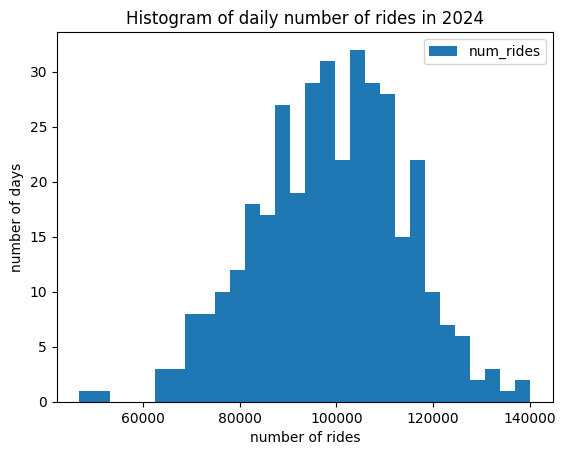

In [12]:
(
    df_dataset.select("num_rides")
    .to_pandas()
    .plot.hist(
        bins=30,
        title="Histogram of daily number of rides in 2024",
        xlabel="number of rides",
        ylabel="number of days",
    )
);

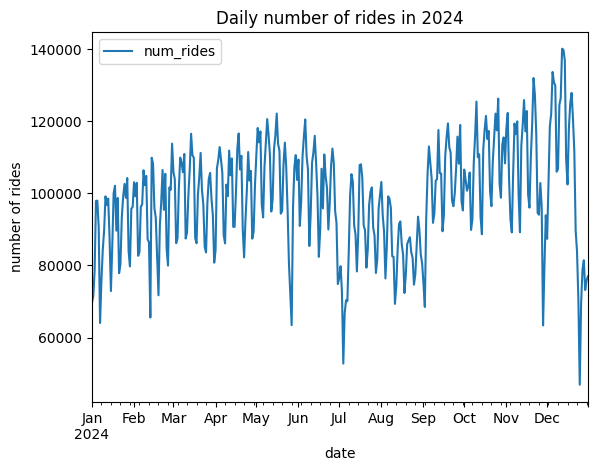

In [13]:
(
    df_dataset.select("date", "num_rides")
    .sort("date")
    .to_pandas()
    .plot.line(
        x="date",
        y="num_rides",
        title="Daily number of rides in 2024",
        xlabel="date",
        ylabel="number of rides",
    )
);